# Appendix C: Data Analysis

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from time import sleep
from scipy.optimize import curve_fit
%matplotlib inline
from math import erf
import pandas as pd

In [2]:
path = 'C:/Users/robtk/OneDrive/Desktop/3rd year Labs/Nuvistor Triode/'

In [3]:
# Define I_F for this experiment run
I_F = 100.0

# Load in data.
I_A =          np.load(path+f"anode currents for I_F {I_F} mA.npy")
V_A_circuit =  np.load(path+f"anode voltages for I_F {I_F} mA.npy")
alloutputs =   np.load(path+f"alloutputs for I_F {I_F} mA.npy")
error_I_A =    np.load(path+f"anode currents errors for I_F {I_F} mA.npy")

In [6]:
I_A

array([-8.0000e-13, -7.0000e-13, -8.0000e-13, -8.0000e-13, -7.0000e-13,
       -7.0000e-13, -9.0000e-13, -8.0000e-13, -8.0000e-13, -6.0000e-13,
       -8.0000e-13, -7.0000e-13, -6.0000e-13, -8.0000e-13, -1.0000e-12,
       -8.0000e-13, -7.0000e-13, -8.0000e-13, -9.0000e-13, -8.0000e-13,
       -9.0000e-13, -1.0000e-12, -8.0000e-13, -8.0000e-13, -1.0000e-12,
       -1.0000e-12, -9.0000e-13, -8.0000e-13, -1.0000e-12, -8.0000e-13,
       -8.0000e-13, -9.0000e-13, -1.0000e-12, -1.1000e-12, -8.0000e-13,
       -9.0000e-13, -8.0000e-13, -8.0000e-13, -1.0000e-12, -1.0000e-12,
       -9.0000e-13, -9.0000e-13, -1.0000e-12, -1.0000e-12, -9.0000e-13,
       -1.1000e-12, -1.1000e-12, -1.0000e-12, -9.0000e-13, -1.0000e-12,
       -1.1000e-12, -1.1000e-12, -1.0000e-12, -1.2000e-12, -1.1000e-12,
       -1.0000e-12, -1.0000e-12, -1.2000e-12, -1.1000e-12, -1.0000e-12,
       -1.1000e-12, -1.2000e-12, -1.1000e-12, -1.1000e-12, -1.3000e-12,
       -1.3000e-12, -1.1000e-12, -1.2000e-12, -1.4000e-12, -1.40

In [4]:
# error_I_A was implemented incorrectly in data collection code. So error_I_A is rebuilt
# The data collection code just used the units of the measurement, not the range of the measurement.
# alloutputs[i*4+1] indexes the range of each measurement

Ranges = ["Range=002nA", "Range=020nA", "Range=200nA", "Range=002uA", "Range=020uA", "Range=200uA", "Range=002mA"]
error_values = [5e-14, 5e-13, 5e-12, 5e-11, 5e-10, 5e-9, 5e-8]

h = 0
while h < len(Ranges):
    i = 0
    
    while i < len(I_A):
        if alloutputs[i*4+1] == Ranges[h]:
            error_I_A[i] = error_values[h]
        i += 1
        
    h += 1

In [5]:
# The instability was so high at the beginning that sometimes the picoammeter measured the current as being reverse polarized.
# So some I_A values have the wrong sign. 
# This is fixed in this cell
i = 0
while i < len(I_A):
    if I_A[i] > 0:
        I_A[i] = -I_A[i]
    i+=1

In [6]:
I_A

array([-8.0000e-13, -7.0000e-13, -8.0000e-13, -8.0000e-13, -7.0000e-13,
       -7.0000e-13, -9.0000e-13, -8.0000e-13, -8.0000e-13, -6.0000e-13,
       -8.0000e-13, -7.0000e-13, -6.0000e-13, -8.0000e-13, -1.0000e-12,
       -8.0000e-13, -7.0000e-13, -8.0000e-13, -9.0000e-13, -8.0000e-13,
       -9.0000e-13, -1.0000e-12, -8.0000e-13, -8.0000e-13, -1.0000e-12,
       -1.0000e-12, -9.0000e-13, -8.0000e-13, -1.0000e-12, -8.0000e-13,
       -8.0000e-13, -9.0000e-13, -1.0000e-12, -1.1000e-12, -8.0000e-13,
       -9.0000e-13, -8.0000e-13, -8.0000e-13, -1.0000e-12, -1.0000e-12,
       -9.0000e-13, -9.0000e-13, -1.0000e-12, -1.0000e-12, -9.0000e-13,
       -1.1000e-12, -1.1000e-12, -1.0000e-12, -9.0000e-13, -1.0000e-12,
       -1.1000e-12, -1.1000e-12, -1.0000e-12, -1.2000e-12, -1.1000e-12,
       -1.0000e-12, -1.0000e-12, -1.2000e-12, -1.1000e-12, -1.0000e-12,
       -1.1000e-12, -1.2000e-12, -1.1000e-12, -1.1000e-12, -1.3000e-12,
       -1.3000e-12, -1.1000e-12, -1.2000e-12, -1.4000e-12, -1.40

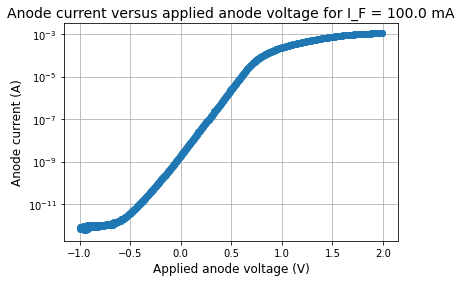

In [7]:
# plot of experimental anode current versus applied voltage with errors.
plt.errorbar(V_A_circuit, (-I_A), error_I_A, 7e-3,
             fmt = 'o')

#plt.plot(V_A_circuit, (-I_A), "o")
plt.xlabel("Applied anode voltage (V)", fontsize = 12)
plt.ylabel("Anode current (A)", fontsize = 12)
plt.title(f"Anode current versus applied anode voltage for I_F = {I_F} mA", fontsize = 14);
#plt.xlim(0.9, 1.055)
plt.yscale("log")
#plt.ylim(.00001,.00002)
#plt.yticks([1e-11, 1e-10, 1e-9, 1e-8, 1e-7]);
plt.grid(True)
#plt.savefig(f"raw i-v for I_F = {I_F} mA", dpi = 100, bbox_inches = "tight");

#### Calculate electron temperature

During the retarding-potential range, Equation 1 is valid which states that the anode current per unit anode length equals the cathode current per unit cathode length

Therefore $\frac{I_L}{I_{LS}} = \frac{I_A}{I_{AS}}$

In [8]:
# Defining equation of linear line of best fit 
def fitfunc(x, m, c):
    return x*m+c

In [9]:
np.log10(0.01)

-2.0

[0.0011129] [5.e-08]
6.200473756304528 0.008085517474351404
[[ 6.53755928e-05 -9.51271698e-07]
 [-9.51271698e-07  9.46972547e-08]]


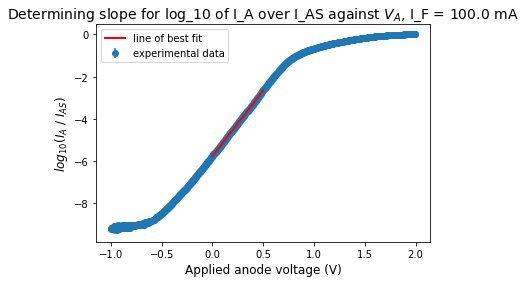

In [10]:
# Find the slope of log10(-I_A/I_AS) versus V_A_circuit graph in order to calculate electron temperature

# The saturated anode current is I_AS which is gotten by inspection of the graph.
index = np.where(np.isclose(V_A_circuit, 1.98))
I_AS = -I_A[index]
error_I_AS = error_I_A[index]

error_log_10_I_A_over_I_AS = np.sqrt( (1/I_A)**2*error_I_A**2 + (-1/I_AS)**2*error_I_AS**2 )

print(I_AS, error_I_AS)

# Defining the start and end of the range of data points used to get the linear best fit slope for calculating T.
start = 200
end   = 300

plt.errorbar(V_A_circuit, (np.log10(-I_A/I_AS)) , error_log_10_I_A_over_I_AS, fmt = "o", label = "experimental data", zorder = 1)

pars1, cov1 = curve_fit(fitfunc, V_A_circuit[start:end],  (np.log10(-I_A/I_AS))[start:end], sigma = error_I_A[start:end]
                       )

plt.plot(np.linspace(V_A_circuit[start],V_A_circuit[end],3), fitfunc(np.linspace(V_A_circuit[start],V_A_circuit[end],3), *pars1),
         linewidth = '2', label = "line of best fit", color = "r", zorder = 2)
print(pars1[0], np.sqrt(cov1[0][0]))
print(cov1)
plt.legend()
plt.xlabel("Applied anode voltage (V)", fontsize = 12)
plt.ylabel("$log_{10}(I_A$ / $I_{AS}$)", fontsize = 12)
plt.title(f"Determining slope for log_10 of I_A over I_AS against $V_A$, I_F = {I_F} mA", fontsize = 14);
#plt.savefig(f"log(I_A over I_AS) against V_A for I_F = {I_F} mA", dpi = 100, bbox_inches = "tight");

In [11]:
# Evaluate electron temperature and its error.
T = 5040/pars1[0]
error_on_slope = np.sqrt(cov1[0,0])

# equation for error_T gotten from general propagation of errors equation.
error_T = np.sqrt((-5040/pars1[0]**2)**2 * error_on_slope**2)
print("Temperature is",T,"+ or -",error_T)

Temperature is 812.8411147415019 + or - 1.0599578831264553


Plot Schottky curve for this electron temperature

In [12]:
# Defining I_L/I_LS using the schottky equation. I_A = Schottky() * I_AS from the theory section
def Schottky1(V_R, T):
    n_A = 1.602176565e-19 * V_R / (1.380649e-23 * T)
    IL_over_ILS = []
    for el in n_A:
        IL_over_ILS = np.append(IL_over_ILS, ( R_A * np.e**(el) * erf(-el/(R_A**2 - 1))**(1/2) + 1 - (erf(-el /(1 - 1/R_A**2)))**(1/2) ))
    
    return IL_over_ILS

890779831605446.2
886484771971229.6
882206200482159.0
877944064075009.6
873698309846840.2
869468885053881.5
865255737111384.5
861058813592901.0
856878062230487.5
852713430913576.8
848564867688532.1
844432320758761.5
840315738484027.0
836215069379170.8
832130262115023.2
828061265516453.6
824008028564077.0
819970500391079.1
815948630284588.6
811942367685500.9
807951662186090.6
803976463531490.5
800016721618876.2
796072386495529.9
792143408360753.1
788229737563344.0
784331324602995.1
780448120127821.2
776580074935633.6
772727139972581.1
768889266333267.8
765066405259765.5
761258508141744.0
757465526515434.2
753687412063605.0
749924116615717.6
746175592145518.2
742441790772816.6
738722664762477.6
735018166522403.0
731328248605957.6
727652863708722.6
723991964669848.6
720345504471284.0
716713436236966.5
713095713232434.1
709492288865086.8
705903116682922.8
702328150374370.9
698767343768484.6
695220650833905.1
691688025678224.0
688169422548385.2
684664795829321.0
681174100044750.0
6776972898

7025712992216.955
6854278531643.436
6685286740336.835
6518727866285.439
6354592189177.482
6192870020444.352
6033551703101.041
5876627611648.019
5722088151960.961
5569923761260.761
5420124907940.863
5272682091532.92
5127585842591.27
4984826722547.7705
4844395323754.254
4706282269209.346
4570478212585.911
4436973838156.571
4305759860602.681
4176827024960.835
4050166106599.7744
3925767911036.8955
3803623273843.6265
3683723060676.093
3566058167021.023
3450619518231.7617
3337398069360.758
3226384805135.858
3117570739768.2246
3010946916996.0215
2906504409871.3916
2804234320783.1626
2704127781232.165
2606175951891.277
2510370022409.2686
2416701211379.334
2325160766202.385
2235739963070.7617
2148430106795.8918
2063222530796.3262
1980108596954.3047
1899079695572.9507
1820127245270.5122
1743242692861.0537
1668417513353.9082
1595643209773.8618
1524911313134.8643
1456213382331.2085
1389541004048.2788
1324885792736.5884
1262239390425.585
1201593466720.2908
1142939718677.3042
1086269870755.0927
1031

90735567101276.78
91038468079570.89
91341442086531.08
91644487577753.95
91947603015074.16
92250786866596.9
92554037606587.0
92857353715746.83
93160733680946.73
93464175995116.39
93767679157612.81
94071241673824.5
94374862055198.86
94678538819567.61
94982270490593.0
95286055598143.08
95589892678246.84
95893780272800.36
96197716929901.14
96501701203385.89
96805731653423.56
97109806845951.81
97413925352797.23
97718085751847.78
98022286626825.64
98326526567497.03
98630804169150.05
98935118033239.66
99239466767021.92
99543848983316.3
99848263301012.4
100152708344714.8
100457182744646.27
100761685136893.4
101066214163180.19
101370768470998.45
101675346713471.77
101979947549401.14
102284569643152.72
102589211664865.45
102893872290150.97
103198550200302.66
103503244082024.4
103807952627742.36
104112674535393.56
104417408508247.7
104722153255272.9
105026907490817.5
105331669934669.1
105636439312151.86
105941214353773.38
106245993795872.84
106550776379662.83
106855560852075.42
107160345965321.83

223657310198917.16
223901188125398.0
224144850894304.8
224388298434149.84
224631530674374.4
224874547545725.53
225117348980340.7
225359934911027.56
225602305272352.94
225844459999487.25
226086399029145.75
226328122298995.53
226569629747889.5
226810921315945.53
227051996944188.75
227292856574936.0
227533500151565.28
227773927618580.7
228014138921666.97
228254134007597.94
228493912824020.44
228733475320110.34
228972821445874.8
229211951152393.12
229450864391948.56
229689561117751.78
229928041284566.38
230166304847459.3
230404351763034.6
230642181989088.72
230879795484158.78
231117192208086.78
231354372121454.06
231591335186413.6
231828081365573.66
232064610622916.4
232300922923619.47
232537018233367.0
232772896519413.22
233008557749631.8
233244001893162.78
233479228920205.0
233714238801576.2
233949031509619.84
234183607017185.3
234417965298719.12
234652106329129.1
234886030084313.9
235119736541676.28
235353225679065.12
235586497475576.62
235819551911098.25
236052388966736.9
2362850086244

329604280090014.1
329734559038479.6
329864677834859.56
329994636634099.56
330124435591665.56
330254074862634.2
330383554601840.0
330512874964927.0
330642036106639.5
330771038182186.25
330899881346481.0
331028565755001.8
331157091562418.6
331285458923938.25
331413667994463.4
331541718929031.4
331669611882646.94
331797347010239.4
331924924466681.25
332052344407131.0
332179606986152.6
332306712358869.56
332433660679819.94
332560452104189.8
332687086786601.94
332813564881759.5
332939886544646.3
333066051929743.25
333192061191888.1
333317914485781.3
333443611965866.94
333569153787145.9
333694540103803.9
333819771070595.06
333944846842177.1
334069767572837.1
334194533417055.3
334319144529620.25
334443601064474.7
334567903176355.9
334692051019506.75
334816044748145.75
334939884516686.6
335063570479364.8
335187102790434.9
335310481603945.75
335433707074158.7
335556779355217.75
335679698601220.25
335802464966179.06
335925078604001.4
336047539668791.1
336169848314520.75
336292004694864.6
3364140

383088689519541.75
383149966168174.75
383211160290901.94
383272271991737.3
383333301374154.75
383394248541663.6
383455113597949.06
383515896646156.5
383576597789728.94
383637217131408.44
383697754774659.25
383758210822166.75
383818585376635.75
383878878541278.25
383939090417936.06
383999221109745.75
384059270718634.56
384119239347244.06
384179127097607.25
384238934071511.94
384298660371168.25
384358306098557.3
384417871354986.5
384477356242378.25
384536760862376.9
384596085315896.25
384655329704931.06
384714494129915.5
384773578692520.0
384832583493297.9
384891508633658.4
384950354213833.75
385009120334834.6
385067807096968.8
385126414600827.94
385184942946778.56
385243392235006.25
385301762565474.5
385360054038496.25
385418266753761.56
385476400811240.3
385534456310314.06
385592433351042.25
385650332032609.0
385708152454378.3
385765894715678.25
385823558915803.4
385881145153643.3
385938653528368.1
385996084138508.75
386053437083042.44
386110712460391.0
386167910369221.5
38622503090814

405896203316207.6
405926268347321.44
405956291598600.06
405986273126287.56
406016212986851.4
406046111236935.4
406075967932031.8
406105783129009.44
406135556883324.94
406165289251450.25
406194980289123.3
406224630052146.5
406254238596475.6
406283805977749.8
406313332251671.25
406342817473793.5
406372261699525.9
406401664984524.94
406431027383919.25
406460348953246.0
406489629747603.44
406518869822090.75
406548069231885.0
406577228032236.7
406606346277525.25
406635424023178.2
406664461323691.8
406693458233713.9
406722414808351.44
406751331101889.9
406780207168873.56
406809043063854.8
406837838841110.5
406866594555123.0
406895310260033.8
406923986010002.9
406952621859348.75
406981217861917.0
407009774071721.9
407038290542703.06
407066767328590.44
407095204483350.3
407123602060757.4
407151960114005.75
407180278697149.5
407208557863168.44
407236797666033.56
407264998158722.44
407293159394782.8
407321281427422.7
407349364309545.44
407377408094399.56
407405412835063.3
407433378584370.56
4074

417144230817326.9
417158552901927.9
417172854799745.9
417187136538686.9
417201398147043.0
417215639652779.94
417229861083860.1
417244062468190.94
417258243833823.94
417272405208380.5
417286546619887.0
417300668096102.7
417314769664737.4
417328851353842.44
417342913190383.1
417356955202622.3
417370977417907.9
417384979863917.75
417398962568097.5
417412925557998.75
417426868861176.25
417440792504805.6
417454696516567.06
417468580923571.75
417482445753191.0
417496291032692.9
417510116789359.75
417523923050309.56
417537709842831.3
417551477193973.1
417565225130797.1
417578953680344.0
417592662869653.4
417606352725749.9
417620023275590.5
417633674545864.25
417647306563812.6
417660919355952.5
417674512949290.25
417688087370257.8
417701642645888.94
417715178802919.06
417728695867656.2
417742193866969.94
417755672827552.25
417769132775544.4
417782573737877.2
417795995740676.44
417809398810425.75
417822782973723.8
417836148256829.3
417849494686091.2
417862822287727.8
417876131087916.75
41788942

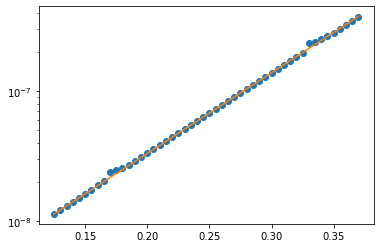

In [21]:
# Using a chi-square goodness of fit test to find the best translate value to make the Schottky curve coincide with experiment

translate = np.arange(0.9,1.3, 0.0001)

start = 225
end   = 275

measured = -I_A[start:end]

best_chi_square = 1e40
best_translate = 0

for el in translate:
    chi_square = 0
    j = 0
    
    expected = Schottky1(V_A_circuit[start:end] - el, T) * I_AS
    
    while j < len(measured):
        #chi_square += ((measured[j] - expected[j]) / error_I_A[start:end][j])**2      
        chi_square += ((measured[j] - expected[j]) / error_I_A[j])**2

        j += 1
    print(chi_square)
    if chi_square < best_chi_square:
        best_chi_square = chi_square
        best_translate = el
        
expected = Schottky1(V_A_circuit[start:end] - best_translate, T) * I_AS   
print(best_translate)
print(best_chi_square)
plt.plot(V_A_circuit[start:end], measured, "o")
plt.plot(V_A_circuit[start:end], expected)
plt.yscale("log")

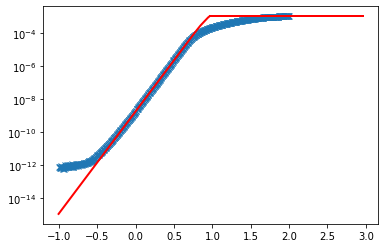

In [17]:
# Making graph of data and Schottky curve, to see if best_translate is actually the optimum translate.

R_A = 1.6

V_R = np.append(np.arange(-1.97, 0.0, 0.05), np.array([0]))
Schottky_curve = Schottky1(V_R, T) * (I_AS)
translate = best_translate

# Plot the theoretical Schottky curve up to V_R = 0
plt.plot(V_R+translate, Schottky_curve, "r", linewidth = "2", zorder = 2)

# Add the horizontal line from V_R = 0 onwards to complete the Schottky curve.
plt.plot(np.linspace(0,2,3)+translate, np.zeros(3) + Schottky1(np.array([0]), T) * (I_AS), "r", linewidth = "2", zorder = 2);


# Plot the experimental data
plt.errorbar(V_A_circuit, (-I_A), error_I_A, 7e-3, fmt = 'x', label = "experimental data", zorder = 1)


plt.yscale("log")
#plt.legend()
#plt.xlim(0.95,1.05)
#plt.ylim(0.0000000000003,.000001)
#plt.xlim(0.502, 0.6)
#plt.xlim(0.0, 0.05);

In [ ]:
# Creating all Schottky curves and translating them to coincide with the experimental data

def Schottky(V_R, T, I_AS):
    n_A = 1.602176565e-19 * V_R / (1.380649e-23 * T)
    IL_over_ILS = []
    for el in n_A:
        IL_over_ILS = np.append(IL_over_ILS, ( R_A * np.e**(el) * erf(-el/(R_A**2 - 1))**(1/2) + 1 - (erf(-el /(1 - 1/R_A**2)))**(1/2) ))
    
    return IL_over_ILS * I_AS

# Set filament currents to access the data
I_F = [65.0, 70.0, 75.0, 80.0, 85.0, 90, 95.0, 100.0]

# I_AS was found through inspection as being the current associated with the following applied voltages for each I_F.
experimental_V_AS = np.array([1.08, 1.03, 1.035, 1.03, 1.05, .97, 1.260, 1.980])

# Define the range on which the slope of the log10(I_A/I_AS) graph is spliced in order to calculate the electron temperature.
Range = [np.arange(225,275,1), np.arange(290,351,1), np.arange(250,351,1), np.arange(250,351,1), 
         np.arange(250,351,1), np.arange(200,301,1), np.arange(200,326,1), np.arange(200,301,1)]

# How much to translate the theoretical Schottky curve by to coincide with experiment for each I_F value
translate = [1.0229, 0.9995, 0.9884, 0.9799, 0.9645, 0.9491, 0.9507, 0.9625]

plt.figure(figsize = (9, 9))

colours = ["b", "g", "orange", "c", "y", "k", "m", "limegreen"]

# Values needed to define error_I_A
Ranges = ["Range=002nA", "Range=020nA", "Range=200nA", "Range=002uA", "Range=020uA", "Range=200uA", "Range=002mA"]
error_values = [5e-14, 5e-13, 5e-12, 5e-11, 5e-10, 5e-9, 5e-8]


i = 0
while i < len(I_F):
    # Load in data.
    I_A =          np.load(path+f"anode currents for I_F {I_F[i]} mA.npy")
    V_A_circuit =  np.load(path+f"anode voltages for I_F {I_F[i]} mA.npy")
    alloutputs =   np.load(path+f"alloutputs for I_F {I_F[i]} mA.npy")
    error_I_A =    np.load(path+f"anode currents errors for I_F {I_F[i]} mA.npy")
    
    # Fixing that some I_A values are so close to zero that they have the wrong sign
    l = 0
    while l < len(I_A):
        if I_A[l] > 0:
            I_A[l] = -I_A[l]
        l+=1
    
    #Define error_I_A correctly
    
    h = 0
    while h < len(Ranges):    
        k = 0
        while k < len(I_A):
            if alloutputs[k*4+1] == Ranges[h]:
                error_I_A[k] = error_values[h]
            k += 1
        h += 1
        
    # Define the index of where the saturated anode current is in the I_A array for each I_F.
    index = np.where(np.isclose(V_A_circuit, experimental_V_AS[i]))
    
    # Get saturated anode current and its error for each I_F.
    I_AS = -I_A[index]
    error_I_AS = error_I_A[np.where(-I_A == I_AS)]

    
    # Compute T and its error for each I_F.
    pars, cov = curve_fit(fitfunc, V_A_circuit[Range[i]],  np.log10(-I_A/I_AS)[Range[i]], sigma = error_I_A[Range[i]])
    T = 5040/pars[0]
    error_on_slope = np.sqrt(cov[0,0])
    error_T = np.sqrt((-5040/pars[0]**2)**2 * error_on_slope**2)
    
    # Plot experimental data.
    plt.errorbar(V_A_circuit, (-I_A), error_I_A, 3.5e-3, fmt = "o", color = colours[i], 
                 zorder = 1, label = f"experimental data for $I_F = {I_F[i]} mA")
    
    # Set x-axis for theoretical data.
    V_R = np.append(np.arange(-2,0,0.01), np.array([0]))

    # plot the Schottky curve and translate it so the slope coincides with the slope of the experimental data.
    plt.plot(V_R + translate[i], Schottky(V_R, T, I_AS), "r", linewidth = "2", zorder = 2)
    
    # The horizontal line at V_R = 0 is plotted to complete the Schottky curve.
    plt.plot(np.linspace(0,1,3) + translate[i], np.zeros(3) + Schottky(np.array([0]), T, I_AS),
             "r", linewidth = "2", zorder = 2);
    
    i += 1

# For entire plot
plt.ylim(10e-13,10e-3)

# For zooming in
#plt.ylim(10e-10, 10e-9)
#plt.xlim(-0.1, 0.95);

plt.yscale("log")
plt.title("Experimental anode currents versus anode voltages paired with Schottky curves", fontsize = 14)
plt.ylabel("Anode current logscale (A)", fontsize = 12)
plt.xlabel("Applied anode voltage (V)", fontsize = 12)
plt.legend();
#plt.savefig("All Schottky curves half zoomed in", dpi = 100, bbox_inches = "tight");

Find I_AS, temperature, effective work functions, and V_C1 for all experimental runs and put them into pandas DataFrames.

In [60]:
(1.622-1.566)/2

0.028000000000000025

In [62]:
# Find I_AS, temperature, effective work functions, and V_C1 for all experimental runs and put them into pandas DataFrames. 

# Defining equation of linear line of best fit 
def fitfunc(x, m, c):
    return x*m+c

# Create the table of I_AS and T for each I_F for the report. 
I_F_list = [65.0, 70.0, 75.0, 80.0, 85.0, 90, 95.0, 100.0]

# Lists needed to calculate error_I_A.
Ranges = ["Range=002nA", "Range=020nA", "Range=200nA", "Range=002uA", "Range=020uA", "Range=200uA", "Range=002mA"]
error_values = [5e-14, 5e-13, 5e-12, 5e-11, 5e-10, 5e-9, 5e-8]
    
# All saturated applied voltages in order to get all I_AS.
V_AS_list = [1.08, 1.03, 1.035, 1.03, 1.05, 0.97, 1.26, 1.98]

# Empty lists to be filled with the final values of I_AS and T
I_AS = []
T = []
error_I_AS = []
error_T = []

# Start and end of ranges for getting slope needed to calculate T.
start_list =[225, 290, 250, 250, 250, 200, 200, 200]
end_list =[275, 350, 350, 350, 350, 300, 325, 300]

# Empty lists to be filled with work functions and contact potential
cathode_phi = []
error_cathode_phi = []
anode_phi = []
error_anode_phi = []
contact_potential_1 = []
error_contact_potential_1 = []


# Define constants needed to get the work functions
# Define the effective cathode area
A_C = 0.201
error_A_C = np.sqrt((2*np.pi*0.381)**2*0.0254**2 +(2*np.pi*0.16256)**2*1.27e-3**2)
# Define the ratio between anode radius and cathode radius R_A
R_A = 1.60
error_R_A = 0.056/2

i = 0
while i < len(I_F_list):
    I_F = I_F_list[i]
    # Load in data.
    I_A =          np.load(path+f"anode currents for I_F {I_F} mA.npy")
    V_A_circuit =  np.load(path+f"anode voltages for I_F {I_F} mA.npy")
    alloutputs =   np.load(path+f"alloutputs for I_F {I_F} mA.npy")

    # Fix some I_A values having the wrong sign
    j = 0
    while j < len(I_A):
        if I_A[j] > 0:
            I_A[j] = -I_A[j]
        j+=1
    
    # define error_I_A
    error_I_A = np.zeros(len(I_A))
    h = 0
    while h < len(Ranges):
        k = 0
        while k < len(I_A):
            if alloutputs[k*4+1] == Ranges[h]:
                error_I_A[k] = error_values[h]
            k += 1
        h += 1
    
    # Define temporary_I_AS
    index = np.where(np.isclose(V_A_circuit, V_AS_list[i]))
    temporary_I_AS = -I_A[index]
    temporary_error_I_AS = error_I_A[index]
    
    # Get fit in order to get slope needed to calculate T.
    pars1, cov1 = curve_fit(fitfunc, V_A_circuit[start_list[i]:end_list[i]],  
                            np.log10(-I_A/temporary_I_AS)[start_list[i]:end_list[i]],
                            sigma = error_I_A[start_list[i]:end_list[i]])
    
    
    # Calculate temporary_T and its error.
    temporary_T = 5040/pars1[0]
    error_on_slope = np.sqrt(cov1[0,0])
    temporary_error_T = np.sqrt((-5040/pars1[0]**2)**2 * error_on_slope**2)

    # Record temporary_I_AS and temporary_T
    I_AS =       np.append(I_AS, f"{temporary_I_AS[0]:.5g}")
    error_I_AS = np.append(error_I_AS, f"{temporary_error_I_AS[0]}")
    T =          np.append(T, temporary_T)
    error_T =    np.append(error_T, temporary_error_T)

    #Calculate work functions and contact potential difference
    # Define constants needed to get the work functions
    I_S = 1.5 * temporary_I_AS
    error_I_S = np.sqrt(1.5**2 * temporary_error_I_AS**2)

    # Define I_AO, the anode current when V_A_circuit = 0
    I_AO = -I_A[np.where(np.isclose(V_A_circuit, 0))]
    error_I_AO = error_I_A[np.where(np.isclose(V_A_circuit, 0))]
    
    # Find cathode_phi
    temporary_cathode_phi = 1.984e-4 * temporary_T * (2.079 + 2 * np.log10(temporary_T) - np.log10(I_S /A_C))

    # Find the uncertainty on cathode_phi
    d_cathode_phi_dT = (1.984e-4*(2.079 + 2 * np.log10(temporary_T) - np.log10(I_S /A_C)) + 
                        1.984e-4 * 2 /np.log(10))
    d_cathode_phi_dI_S = 1.984e-4 * temporary_T * 1/( -I_S * np.log(10) )
    d_cathode_phi_dA_C = 1.984e-4 * temporary_T * 1/( A_C * np.log(10) )

    temporary_error_cathode_phi = np.sqrt( d_cathode_phi_dT**2 * temporary_error_T**2 + 
                                 d_cathode_phi_dI_S**2 * error_I_S**2 +
                                 d_cathode_phi_dA_C**2 * error_A_C**2 )

    # Find anode_phi
    temporary_anode_phi = 1.984e-4 * temporary_T * (2.079 + np.log10(R_A) + 2 * np.log10(temporary_T) - np.log10(I_AO / A_C))

    # Find the uncertainty on anode_phi
    d_anode_phi_dT = ( 1.984e-4*(2.079 + np.log10(R_A)+ 2*np.log10(temporary_T) - np.log10(I_AO / A_C)) + 
                       1.984e-4 * 2 / np.log(10))
    d_anode_phi_dR_A = 1.984e-4 * temporary_T * 1/(R_A * np.log(10))
    d_anode_phi_dI_AO = 1.984e-4 * temporary_T * -1/(I_AO * np.log(10))
    d_anode_phi_dA_C = 1.984e-4 * temporary_T * 1/(A_C * np.log(10))

    temporary_error_anode_phi = np.sqrt( d_anode_phi_dT**2 * temporary_error_T**2 + 
                               d_anode_phi_dR_A**2 * error_R_A**2 +
                               d_anode_phi_dI_AO**2 * error_I_AO**2 +
                               d_anode_phi_dA_C**2 * error_A_C**2 )

    # Determine contact_potential_1
    temporary_contact_potential_1 = temporary_anode_phi - temporary_cathode_phi

    # Find the uncertainty on contact_potential_1
    d_contact_potential_1_danode_phi = - temporary_cathode_phi
    d_contact_potential_1_dcathode_phi = temporary_anode_phi

    temporary_error_contact_potential_1 = np.sqrt( d_contact_potential_1_danode_phi**2 * temporary_error_anode_phi**2 +
                                         d_contact_potential_1_dcathode_phi**2 * temporary_error_cathode_phi**2)
    
    # Append work functions and contact potential to respective lists
    cathode_phi =               np.append(cathode_phi, temporary_cathode_phi)
    error_cathode_phi =         np.append(error_cathode_phi, temporary_error_cathode_phi)
    anode_phi =                 np.append(anode_phi, temporary_anode_phi)
    error_anode_phi =           np.append(error_anode_phi, temporary_error_anode_phi)
    contact_potential_1 =       np.append(contact_potential_1, temporary_contact_potential_1)
    error_contact_potential_1 = np.append(error_contact_potential_1, temporary_error_contact_potential_1)
        
    i += 1

# I_AS and T table
Dictionary_1 = {"I_F (mA)": I_F_list, "I_AS (A)": I_AS, "error_I_AS": error_I_AS, "T (K)": T, "error_T (K)": error_T}
    
Table_1 = pd.DataFrame(Dictionary_1)
print(Table_1)
    
# Work functions and contact potential table
Dictionary_2 = {"I_F (mA)": I_F_list, "\phi_{CE} (V)": cathode_phi, "error \phi_{CE} (V)": error_cathode_phi,
                "\phi{AE} (V)": anode_phi, "error \phi_{AE} (V)": error_anode_phi}
Table_2 = pd.DataFrame(Dictionary_2)
print(Table_2)

# Contact potential tables
Dictionary_3 = {"I_F (mA)": I_F_list, "contact potential": contact_potential_1,
                "error contact potential": error_contact_potential_1}
Table_3 = pd.DataFrame(Dictionary_3)
print(Table_3)


   I_F (mA)    I_AS (A) error_I_AS       T (K)  error_T (K)
0      65.0   8.606e-08      5e-12  553.502948     0.680436
1      70.0   5.313e-07      5e-11  580.774459     0.527049
2      75.0   2.938e-06      5e-10  619.131474     1.499095
3      80.0  1.2804e-05      5e-10  656.040363     0.696050
4      85.0   5.008e-05      5e-09  693.500760     0.582181
5      90.0   0.0001378      5e-09  735.785781     0.552325
6      95.0   0.0004427      5e-08  768.929581     1.019878
7     100.0   0.0011129      5e-08  812.841115     1.059958
   I_F (mA)  \phi_{CE} (V)  error \phi_{CE} (V)  \phi{AE} (V)  \
0      65.0       1.510784             0.014565      2.105095   
1      70.0       1.498945             0.015211      2.317687   
2      75.0       1.513534             0.016612      2.366650   
3      80.0       1.527099             0.017192      2.478748   
4      85.0       1.539437             0.018134      2.521199   
5      90.0       1.576635             0.019226      2.553830   
6    

In [63]:
# Copy paste tables to lab report
print(Table_1.to_latex(index = False))
print(Table_2.to_latex(index = False))
print(Table_3.to_latex(index = False))

\begin{tabular}{rllrr}
\toprule
 I\_F (mA) &   I\_AS (A) & error\_I\_AS &      T (K) &  error\_T (K) \\
\midrule
     65.0 &  8.606e-08 &      5e-12 & 553.502948 &     0.680436 \\
     70.0 &  5.313e-07 &      5e-11 & 580.774459 &     0.527049 \\
     75.0 &  2.938e-06 &      5e-10 & 619.131474 &     1.499095 \\
     80.0 & 1.2804e-05 &      5e-10 & 656.040363 &     0.696050 \\
     85.0 &  5.008e-05 &      5e-09 & 693.500760 &     0.582181 \\
     90.0 &  0.0001378 &      5e-09 & 735.785781 &     0.552325 \\
     95.0 &  0.0004427 &      5e-08 & 768.929581 &     1.019878 \\
    100.0 &  0.0011129 &      5e-08 & 812.841115 &     1.059958 \\
\bottomrule
\end{tabular}

\begin{tabular}{rrrrr}
\toprule
 I\_F (mA) &  \textbackslash phi\_\{CE\} (V) &  error \textbackslash phi\_\{CE\} (V) &  \textbackslash phi\{AE\} (V) &  error \textbackslash phi\_\{AE\} (V) \\
\midrule
     65.0 &       1.510784 &             0.014565 &      2.105095 &             0.015005 \\
     70.0 &       1.498945 &   

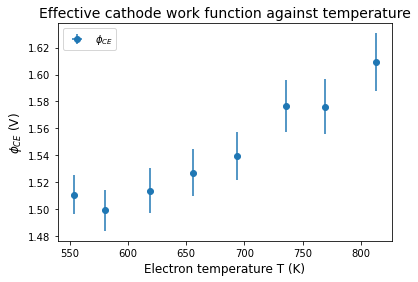

In [64]:
# Plot of effective cathode work function.
plt.errorbar(Table_1["T (K)"], Table_2["\phi_{CE} (V)"], Table_2["error \phi_{CE} (V)"],  Table_1["error_T (K)"],
             fmt = "o", label = "$\phi_{CE}$")

plt.legend(loc = 'upper left')
plt.title("Effective cathode work function against temperature", fontsize = 14)
plt.xlabel("Electron temperature T (K)", fontsize = 12)
plt.ylabel("$\phi_{CE}$ (V)", fontsize = 12)
plt.savefig("Cathode work function", dpi = 100, bbox_inches = "tight");

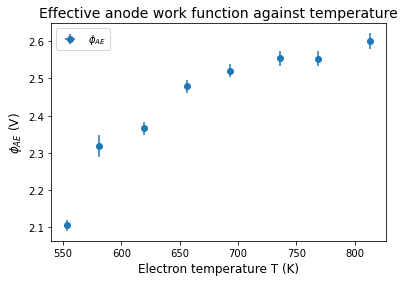

In [65]:
# Plot of effective anode work function.

plt.errorbar(Table_1["T (K)"], Table_2["\phi{AE} (V)"], Table_2["error \phi_{AE} (V)"], Table_1["error_T (K)"],
             fmt = "o", label = "$\phi_{AE}$")
plt.legend()
plt.title("Effective anode work function against temperature", fontsize = 14)
plt.xlabel("Electron temperature T (K)", fontsize = 12)
plt.ylabel("$\phi_{AE}$ (V)", fontsize = 12)
plt.savefig("Anode work function", dpi = 100, bbox_inches = "tight");

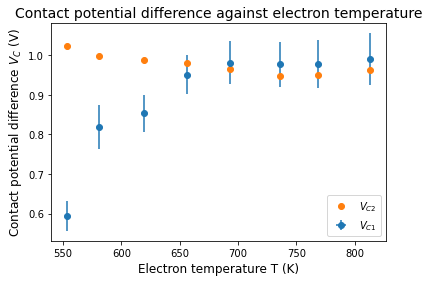

In [66]:
# Comparison plot of contact potential difference.
plt.errorbar(Table_1["T (K)"], Table_3["contact potential"], Table_3["error contact potential"], Table_1["error_T (K)"],
             fmt = "o", label = "$V_{C1}$")
plt.plot(Table_1["T (K)"], [1.0229, 0.9995, 0.9884, 0.9799, 0.9645, 0.9491, 0.9507, 0.9625], 
         "o", label = "$V_{C2}$")

plt.title("Contact potential difference against electron temperature", fontsize = 14)
plt.xlabel("Electron temperature T (K)", fontsize = 12)
plt.ylabel("Contact potential difference $V_C$ (V)", fontsize = 12)
plt.legend();
plt.savefig("Contact potential comparison", dpi = 100, bbox_inches = "tight");

In [67]:
# Find average effective work functions
average_phi_CE = sum(Table_2["\phi_{CE} (V)"])/len(Table_2["\phi_{CE} (V)"])
average_phi_AE = sum(Table_2["\phi{AE} (V)"])/len(Table_2["\phi{AE} (V)"])
average_T = sum(Table_1["T (K)"])/len(Table_1["T (K)"])

# Find errors on effective work functions
error_average_phi_CE = np.sqrt( (1/len((Table_2["\phi_{CE} (V)"])))**2 * (sum(Table_2["error \phi_{CE} (V)"]**2) ) )
error_average_phi_AE = np.sqrt( (1/len((Table_2["\phi{AE} (V)"])))**2 * (sum(Table_2["error \phi_{AE} (V)"]**2) ) )
error_average_T = np.sqrt( (1/len((Table_1["T (K)"])))**2 * (sum(Table_1["error_T (K)"]**2) ) )


print(average_phi_CE, "\pm", error_average_phi_CE)
print(average_phi_AE, "\pm", error_average_phi_AE)
print(average_T, "\pm", error_average_T)


1.5440001331850106 \pm 0.006342874737935671
2.43708153283899 \pm 0.007164031881373349
677.5633099897219 \pm 0.3132541704048745


In [68]:
# Find average effective work functions
average_V_C1 = sum(Table_3["contact potential"])/len(Table_3["contact potential"])
average_V_C2 = sum([1.0229, 0.9995, 0.9884, 0.9799, 0.9645, 0.9491, 0.9507, 0.9625])/ 8

# Find errors on effective work functions
error_average_V_C1 = np.sqrt( (1/len((Table_3["contact potential"])))**2 * (sum(Table_3["error contact potential"]**2) ) )
error_average_V_C2 = np.sqrt( (1/8)**2 * 3.5e-3**2) * 8 


print(average_V_C1, "\pm", error_average_V_C1)
print(average_V_C2, "\pm", error_average_V_C2)
print(average_T, "\pm", error_average_T)


0.893081399653979 \pm 0.01919732161376481
0.9771875000000002 \pm 0.0035
677.5633099897219 \pm 0.3132541704048745


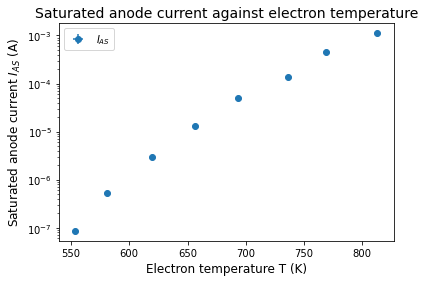

In [69]:
Table_1["I_AS (A)"] = Table_1["I_AS (A)"].astype(float)
Table_1["error_I_AS"] = Table_1["error_I_AS"].astype(float)


plt.errorbar(Table_1["T (K)"], Table_1["I_AS (A)"],Table_1["error_I_AS"], Table_1["error_T (K)"],
             fmt = "o", label = "$I_{AS}$")

plt.title("Saturated anode current against electron temperature", fontsize = 14)
plt.xlabel("Electron temperature T (K)", fontsize = 12)
plt.ylabel("Saturated anode current $I_{AS}$ (A)", fontsize = 12)
plt.yscale("log")
plt.legend();
plt.savefig("I_AS vs T graph", dpi = 100, bbox_inches = "tight");